# Monte Carlo 1 notebook

## "Random" number generator

Computers cannot generate truly random numbers. They use deterministic equations to create series of numbers that appear random. An example of such an equation is:

$$
x' = (a*x+c) \text{mod} (m)
$$

where $a$, $c$, and $m$ are carefully selected to produce the random-looking series. The initial value of $x$ is called the seed. The computer value $x'$ becomes the seed for the next one in the series.

The graphs on the left show how $x'$ change for each iteration. On the right, we show the distribution of the results.

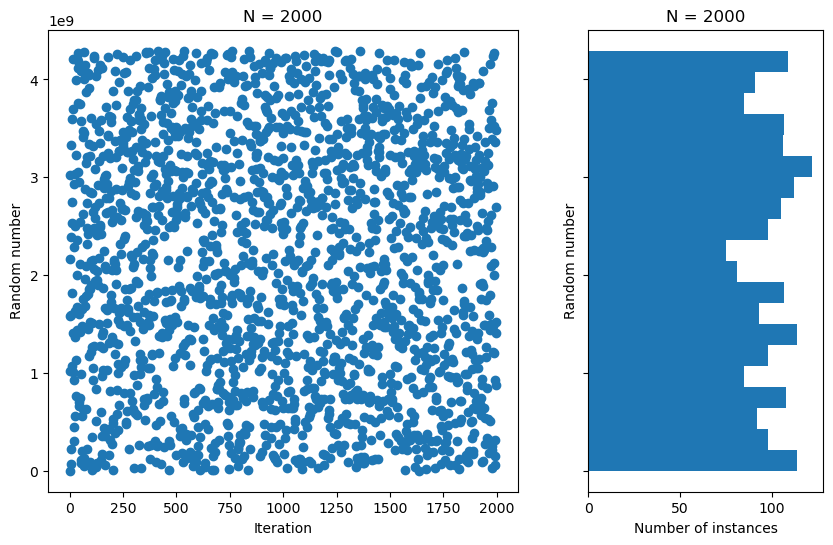

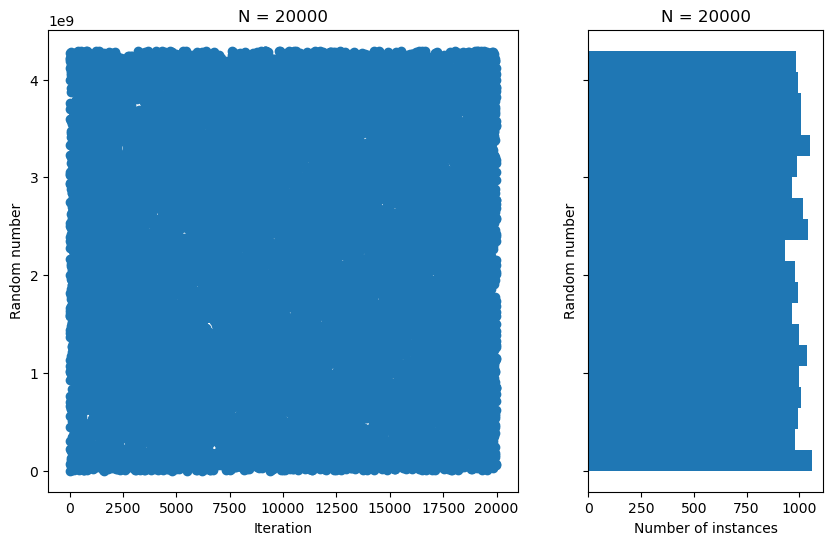

In [35]:
import numpy as np
import matplotlib.pyplot as plt 

N = 2000
N_2 = 20000
a = 1664525
c = 1013904223
m = 4294967296

def rand(a, c, m, seed, N):
    results = np.empty(N, dtype="int")
    results[0] = seed

    iterations = np.linspace(0,N-1,num=N)

    for i in range(N-1):
        results[i+1] = (a*results[i]+c)%m 

    return [iterations, results]

iterations, random_numbers = rand(a, c, m, 1, N)
iterations_2, random_numbers_2 = rand(a, c, m, 1, N_2)

fig1, axes1 = plt.subplots(1,2, figsize=(10,6), sharey=True,
                            gridspec_kw={"width_ratios": [1, 0.5]})
axes1[0].plot(iterations, random_numbers,"o")
axes1[0].set_xlabel("Iteration")
axes1[0].set_ylabel("Random number")
axes1[0].set_title(f"N = {N}")

axes1[1].hist(random_numbers, bins=20, orientation="horizontal")
axes1[1].set_xlabel("Number of instances")
axes1[1].set_ylabel("Random number")
axes1[1].set_title(f"N = {N}")

fig2, axes2 = plt.subplots(1,2, figsize=(10,6), sharey=True,
                            gridspec_kw={"width_ratios": [1, 0.5]})
axes2[0].plot(iterations_2, random_numbers_2,"o")
axes2[0].set_xlabel("Iteration")
axes2[0].set_ylabel("Random number")
axes2[0].set_title(f"N = {N_2}")

axes2[1].hist(random_numbers_2, bins=20, orientation="horizontal")
axes2[1].set_xlabel("Number of instances")
axes2[1].set_ylabel("Random number")
axes2[1].set_title(f"N = {N_2}")
plt.show()

## Importance of the parameters

In the example above, the constants $a$, $c$, and $m$ where well selected. By changing them only a little, we can create series of numbers that do not look random anymore. Below:

$ a = 1664525 \rightarrow 1664524$

and

$c = 1013904223 \rightarrow 1013904222$.

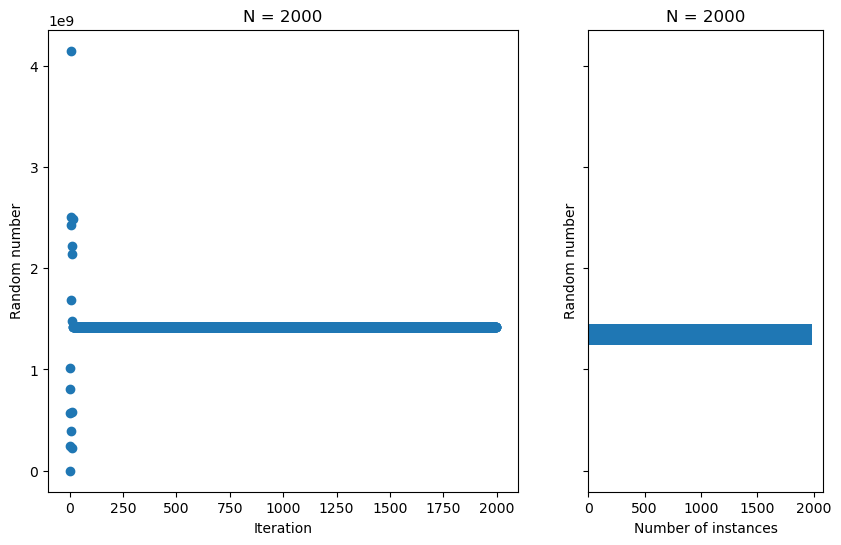

In [36]:
import numpy as np
import matplotlib.pyplot as plt 

N = 2000
a = 1664524         # Compared to 1664525 (-1)
c = 1013904222      # Compared to 1013904223 (-1)
m = 4294967296

iterations, random_numbers = rand(a, c, m, 1, N)

fig1, axes1 = plt.subplots(1,2, figsize=(10,6), sharey=True,
                            gridspec_kw={"width_ratios": [1, 0.5]})
axes1[0].plot(iterations, random_numbers,"o")
axes1[0].set_xlabel("Iteration")
axes1[0].set_ylabel("Random number")
axes1[0].set_title(f"N = {N}")

axes1[1].hist(random_numbers, bins=20, orientation="horizontal")
axes1[1].set_xlabel("Number of instances")
axes1[1].set_ylabel("Random number")
axes1[1].set_title(f"N = {N}")

plt.show()


## Seeds

The seeds determine the whole series of number. If we run the equation with the same seed, we get the values. This is valuable for testing algorithms. If we change the seed, we get different series of values. Often, the libraries in programming language that create random numbers ensure that the seed changes between calls unless forced.

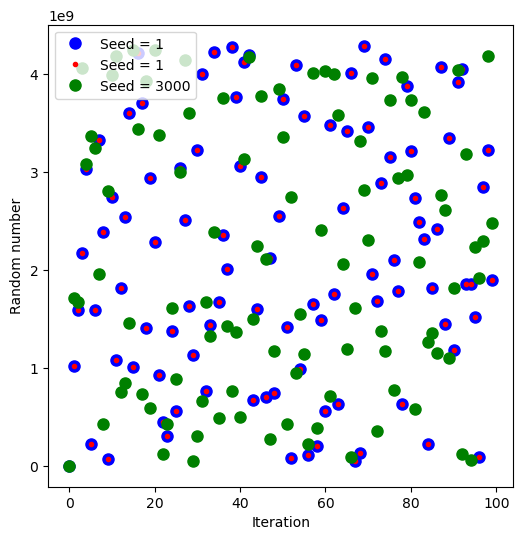

In [37]:
import numpy as np
import matplotlib.pyplot as plt 

N = 100
a = 1664525
c = 1013904223
m = 4294967296
seed_1 = 1
seed_2 = 1
seed_3 = 3000

iterations_1, random_numbers_1 = rand(a, c, m, seed_1, N)
iterations_2, random_numbers_2 = rand(a, c, m, seed_2, N)
iterations_3, random_numbers_3 = rand(a, c, m, seed_3, N)

fig1, axes1 = plt.subplots(1,1, figsize=(6,6))
axes1.plot(iterations_1, random_numbers_1, "o", color="b", markersize=8, label=f"Seed = {seed_1}")
axes1.plot(iterations_2, random_numbers_2, "o", color="r", markersize=3, label=f"Seed = {seed_2}")
axes1.plot(iterations_3, random_numbers_3, "o", color="g", markersize=8, label=f"Seed = {seed_3}")
axes1.legend(loc='upper left')
axes1.set_xlabel("Iteration")
axes1.set_ylabel("Random number")

plt.show()


## Numpy library

The numpy library has a collection of functions available to generate and use random numbers. In the example below, we assume a `uniform` distribution similar to the examples above.

In [46]:
import numpy as np 

# Create the random number generator.
rng = np.random.default_rng()
# rng = np.random.default_rng(seed=42)

# Create a single float number between 0 and 1
print(f"A random number between 0 and 1 is {rng.random():.6f}.")

# Create an array of size 20 of integer numbers between 3 and 111 
print(f"An array of 20 integer numbers between 3 and 111 is {rng.integers(3, 111, 20)}")

# Create an array of size 20 of float numbers between 3 and 111 
print(f"An array of 20 float numbers between 3 and 111 is {rng.uniform(3, 111, 20)}")
 

A random number between 0 and 1 is 0.752179.
An array of 20 integer numbers between 3 and 111 is [ 54  17  74  56   6  71  82  58  31  97  32  31  11 109  97  48  53  25
  90  94]
An array of 20 float numbers between 3 and 111 is [ 29.84892072 107.71454072 107.34049169  31.6943269  105.1101208
  35.62584209  80.71218993   6.90303901  59.76088785  53.03044139
 101.20967914  51.6644744   35.2992644   50.28128277  70.39097176
  96.11954073  60.55684263   5.30268108  90.00801607  25.20104972]


## Isotope decay

For an isotope with a half-life $\tau$, the number of isotopes left ($N(t)$) after a time $t$ from an initial population of $N(0)$ is given by:

$$
N(t) = N(0)2^{-t/\tau}
$$

The probability that any one isotope has not decayed is thus given by:

$$
R(t) = \frac{N(t)}{N(0)} = 2^{-t/\tau}
$$

If we consider the probability of decay ($P(t)$), we get:

$$
P(t) + R(t) = 1
$$

Hence:

$$
P(t) = 1-2^{-t/\tau}
$$

We can use that to track the population of $^{208}$ Tl atoms (Thallium) with a half-life of 3.053 minutes that decayse into $^{208}$ Pb (lead).

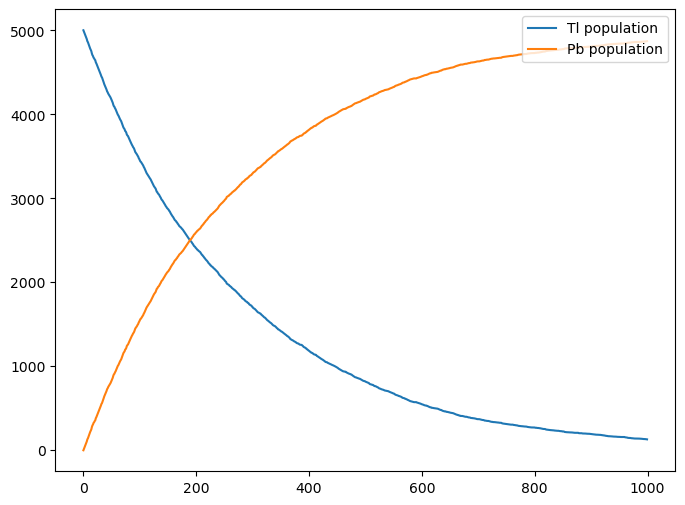

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 

# Constants
Ntl = 5000          # Initial number of thallium atoms
NPb = 0             # Initial number of lead atoms
tau = 3.053*60      # half-life in seconds
dt = 1.0            # Time interval to calculate the odds of decay
p = 1-2**(-dt/tau)  # Odds of decay during interval dt
Ntime = 1000        # Number of time points

# Create rng
rng = np.random.default_rng()

# Create arrays
time = np.linspace(0, (Ntime-1)*dt, num=Ntime)
Tl_population = np.empty(Ntime, dtype='int')
Pb_population = np.empty(Ntime, dtype='int')

# Check at every time point
for i in range(Ntime):
    Tl_population[i] = Ntl
    Pb_population[i] = NPb

    # Calculate the number of atoms that decay
    decay = 0
    for j in range(Ntl):
        if rng.random() < p:
            decay += 1
    Ntl -= decay
    NPb += decay

fig, axes = plt.subplots(1, 1, figsize=(8,6))
axes.plot(Tl_population, label="Tl population")
axes.plot(Pb_population, label="Pb population")
axes.legend(loc='upper right')

plt.show()


You can change the number of starting atoms above. If you reduce it, the curves will be less smooth. 

## Probability distribution

- For an isotope to decay between times $t$ and $t+dt$:

$$
p(t) = 2^{-t/\tau}\frac{\ln(2)}{\tau}dt
$$

- For a Gaussian (normal) distribution:

$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}
$$

- For the Boltzmann distribution that calculates the probability of a discrete energy level to be populated in a sample at a given temperature:

$$
p(T) \propto e^{-E/k_BT}
$$

- For the Maxwell-Boltzmann distribution that calculates the probability of a particle at given temperature to have a certain speed:

$$
f(v) \propto v^2 e^{-\frac{mv^2}{2k_B T}}
$$

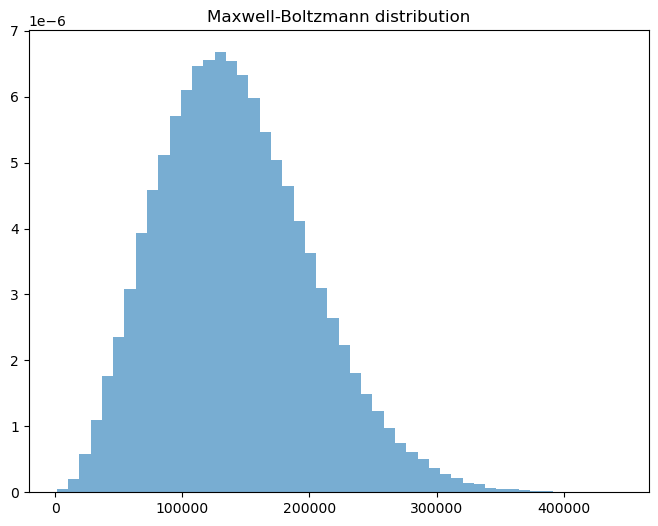

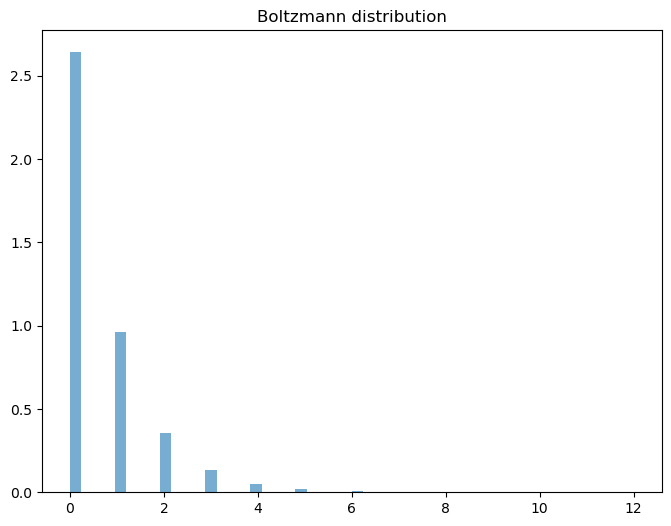

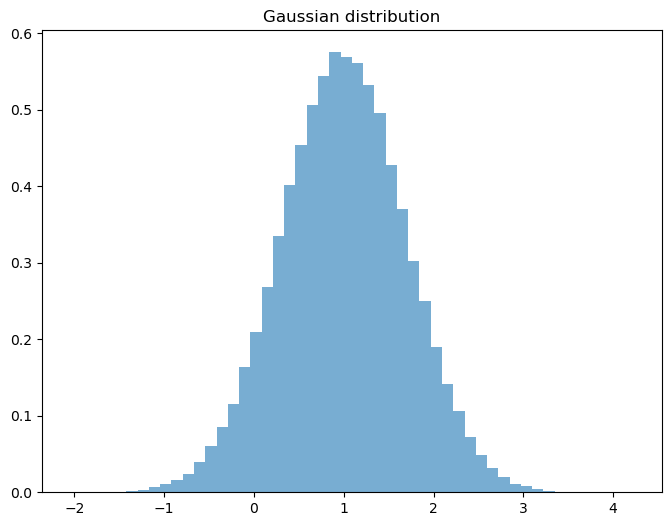

In [67]:
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt 

N = 100000

max_boltz = sp.stats.maxwell.rvs(scale=89000, size=N)
boltz = sp.stats.boltzmann.rvs(1, 19, size=N)
gaussian = sp.stats.norm.rvs(loc = 1.0, scale=0.69, size=N)

fig1, axes1 = plt.subplots(1, 1, figsize=(8,6))
axes1.hist(max_boltz, bins=50, density=True, alpha=0.6)
axes1.set_title("Maxwell-Boltzmann distribution")

fig2, axes2 = plt.subplots(1, 1, figsize=(8,6))
axes2.hist(boltz, bins=50, density=True, alpha=0.6)
axes2.set_title("Boltzmann distribution")

fig3, axes3 = plt.subplots(1, 1, figsize=(8,6))
axes3.hist(gaussian, bins=50, density=True, alpha=0.6)
axes3.set_title("Gaussian distribution")

plt.show()
